Saving flower_sample.png to flower_sample.png


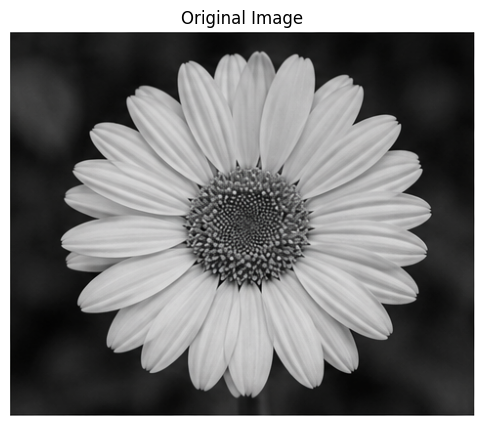

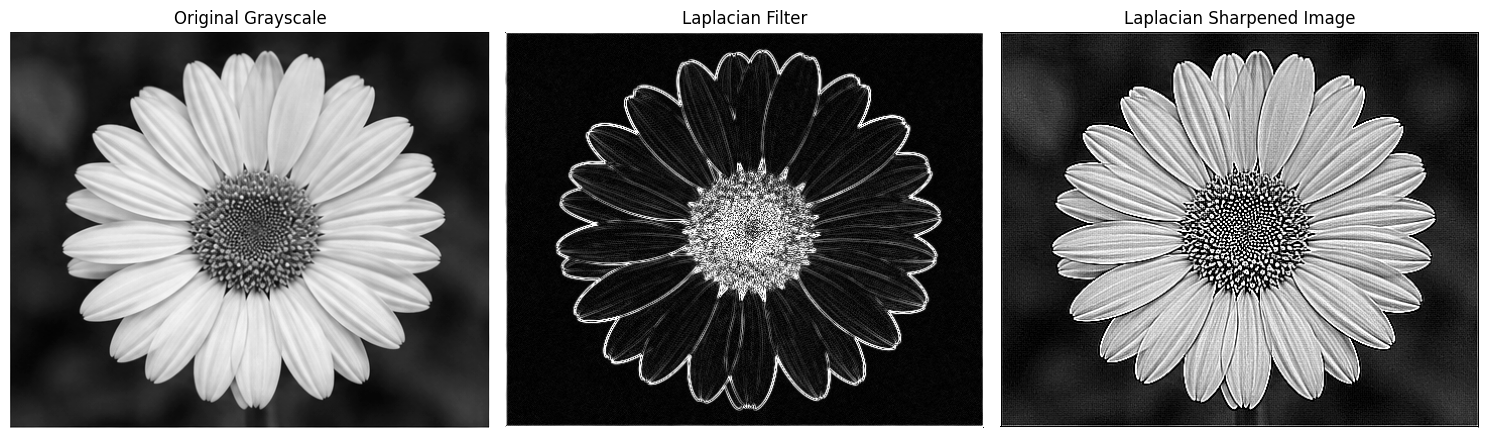

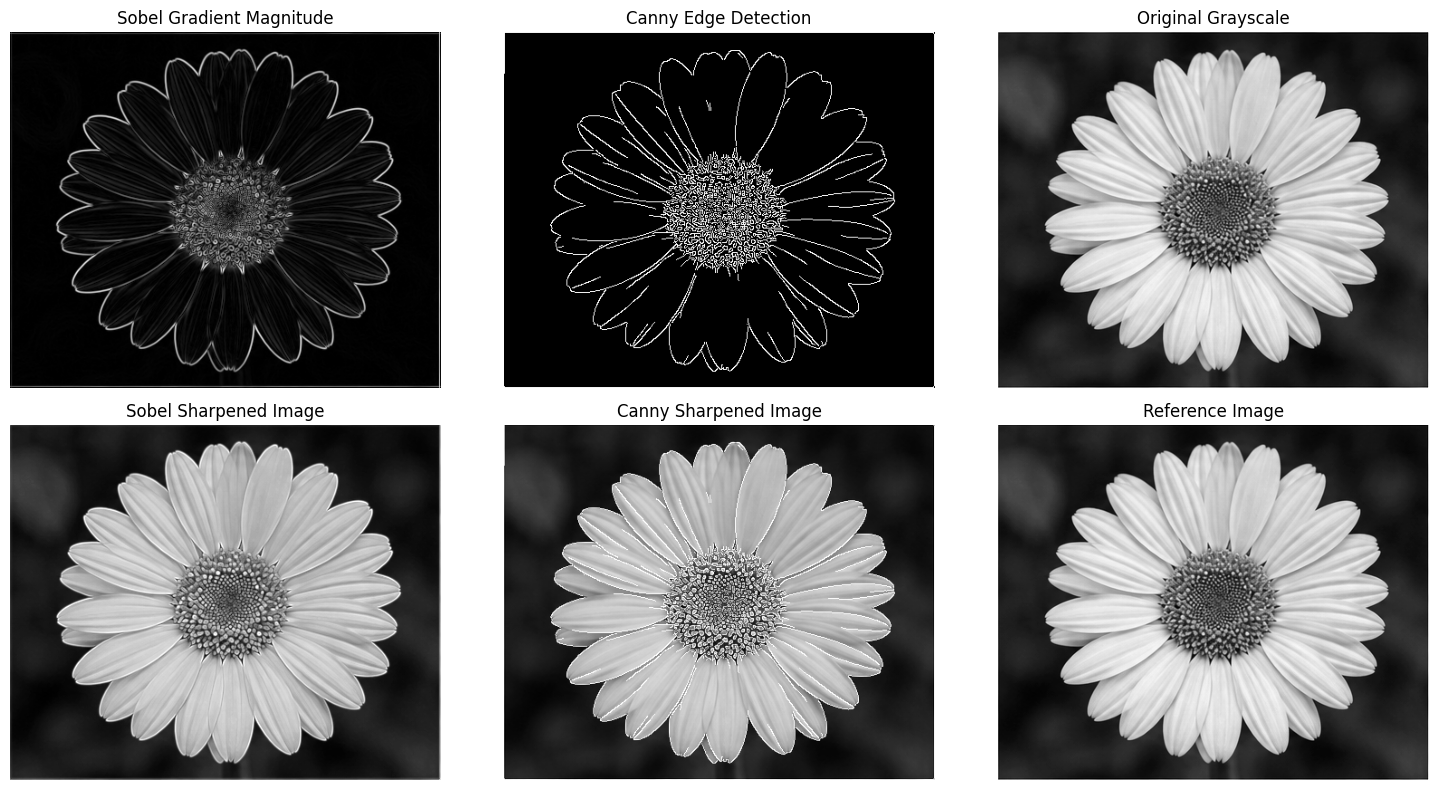

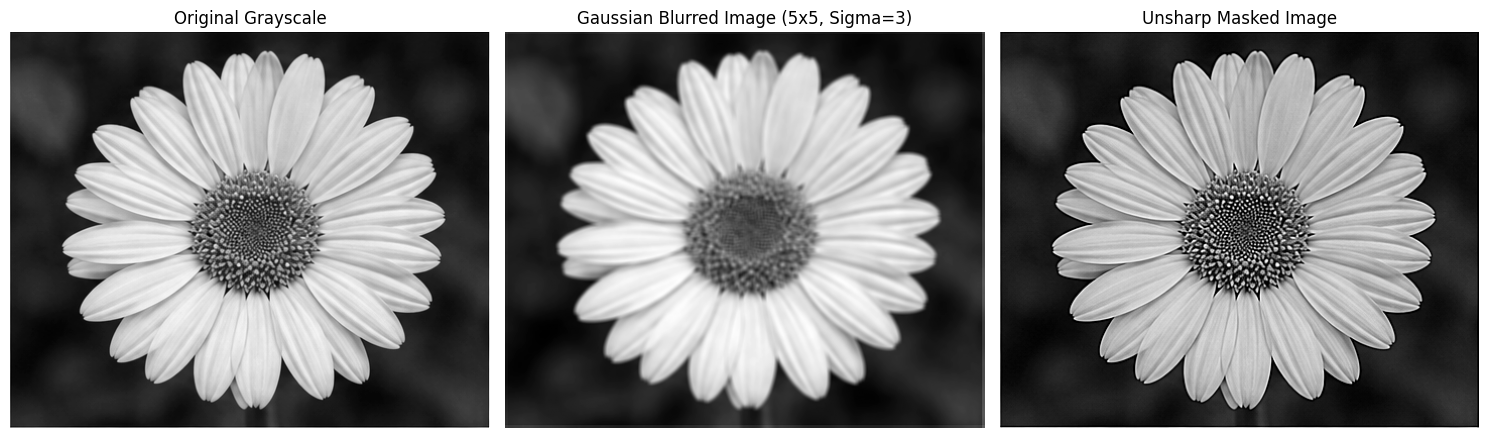

All image sharpening operations completed successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:



import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files


uploaded = files.upload()
image_path = next(iter(uploaded))


img = cv2.imread(image_path)

if img is None:
    raise ValueError("Image could not be loaded. Please upload a valid image.")


original = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

plt.figure(figsize=(6, 6))
plt.imshow(original)
plt.title("Original Image")
plt.axis("off")
plt.show()


#1

laplacian = cv2.Laplacian(gray, cv2.CV_64F, ksize=3)


laplacian_display = cv2.convertScaleAbs(laplacian)


laplacian_sharp = gray.astype(np.float32) - laplacian
laplacian_sharp = np.clip(laplacian_sharp, 0, 255).astype(np.uint8)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(gray, cmap="gray")
plt.title("Original Grayscale")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(laplacian_display, cmap="gray")
plt.title("Laplacian Filter")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(laplacian_sharp, cmap="gray")
plt.title("Laplacian Sharpened Image")
plt.axis("off")

plt.tight_layout()
plt.show()



#2

sobel_x = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)


sobel_magnitude = np.sqrt(sobel_x**2 + sobel_y**2)


sobel_display = cv2.normalize(
    sobel_magnitude, None, 0, 255, cv2.NORM_MINMAX
).astype(np.uint8)


sobel_sharp = gray.astype(np.float32) + 0.5 * sobel_display
sobel_sharp = np.clip(sobel_sharp, 0, 255).astype(np.uint8)


canny_edges = cv2.Canny(gray, 100, 200)


canny_sharp = gray.astype(np.float32) + 0.5 * canny_edges
canny_sharp = np.clip(canny_sharp, 0, 255).astype(np.uint8)

plt.figure(figsize=(15, 8))

plt.subplot(2, 3, 1)
plt.imshow(sobel_display, cmap="gray")
plt.title("Sobel Gradient Magnitude")
plt.axis("off")

plt.subplot(2, 3, 2)
plt.imshow(canny_edges, cmap="gray")
plt.title("Canny Edge Detection")
plt.axis("off")

plt.subplot(2, 3, 3)
plt.imshow(gray, cmap="gray")
plt.title("Original Grayscale")
plt.axis("off")

plt.subplot(2, 3, 4)
plt.imshow(sobel_sharp, cmap="gray")
plt.title("Sobel Sharpened Image")
plt.axis("off")

plt.subplot(2, 3, 5)
plt.imshow(canny_sharp, cmap="gray")
plt.title("Canny Sharpened Image")
plt.axis("off")

plt.subplot(2, 3, 6)
plt.imshow(gray, cmap="gray")
plt.title("Reference Image")
plt.axis("off")

plt.tight_layout()
plt.show()



#3

blurred = cv2.GaussianBlur(gray, (5, 5), sigmaX=3)


unsharp_mask = gray.astype(np.float32) - blurred.astype(np.float32)


unsharp_sharp = gray.astype(np.float32) + unsharp_mask


unsharp_sharp = np.clip(unsharp_sharp, 0, 255).astype(np.uint8)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(gray, cmap="gray")
plt.title("Original Grayscale")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(blurred, cmap="gray")
plt.title("Gaussian Blurred Image (5x5, Sigma=3)")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(unsharp_sharp, cmap="gray")
plt.title("Unsharp Masked Image")
plt.axis("off")

plt.tight_layout()
plt.show()



cv2.imwrite("laplacian_sharpened.png", laplacian_sharp)
cv2.imwrite("sobel_sharpened.png", sobel_sharp)
cv2.imwrite("canny_sharpened.png", canny_sharp)
cv2.imwrite("unsharp_masked.png", unsharp_sharp)

print("All image sharpening operations completed successfully!")


files.download("laplacian_sharpened.png")
files.download("sobel_sharpened.png")
files.download("canny_sharpened.png")
files.download("unsharp_masked.png")
